# SCIKIT-LEARN MASTERY — NOTEBOOK 6
## Chapters 26–31: Advanced Search Strategies → Evaluation Metrics → Confusion Matrix → ROC/PR Analysis → Threshold Optimization → Calibration

Continuing directly from Notebook 5.

### SCIKIT-LEARN MASTERY PROGRESS
- [x] Chapters 1–25 *(Notebooks 1–5)*
- [x] Advanced Search Strategies
- [x] Evaluation Metrics
- [x] Confusion Matrix
- [x] ROC / PR Analysis
- [x] Threshold Optimization
- [x] Calibration


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
np.random.seed(42)


---
# CHAPTER 26 — ADVANCED SEARCH STRATEGIES

## 1. Concept
Beyond `GridSearchCV`/`RandomizedSearchCV`'s "search blindly, evaluate every candidate independently" approach, **Bayesian optimization** uses the *results of previous trials* to intelligently choose the next hyperparameter combination to try — spending less budget on clearly-unpromising regions of the search space.

## 2. The Landscape
| Approach | How it chooses the next trial | Tool |
|---|---|---|
| Manual tuning | Human intuition/experience | — |
| Grid search | Every combination, exhaustively | `GridSearchCV` |
| Random search | Uniformly random sampling | `RandomizedSearchCV` |
| Bayesian optimization | A probabilistic model of "which regions look promising," updated after every trial | **Optuna** (industry standard), scikit-optimize |

## 3. A Conceptual Optuna Sketch (not runnable here — Optuna is an external library, not part of Scikit-learn itself)
```python
import optuna
from sklearn.model_selection import cross_val_score

def objective(trial):
    n_estimators = trial.suggest_int("n_estimators", 50, 500)
    max_depth = trial.suggest_int("max_depth", 2, 15)
    model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=42)
    return cross_val_score(model, X, y, cv=5, scoring="roc_auc").mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=100)
print(study.best_params)
```
Optuna's `TPESampler` (its default) builds a probabilistic model of which hyperparameter regions tend to score well, then samples the *next* trial preferentially from those regions — meaning, for a **fixed trial budget**, Optuna typically finds a meaningfully better result than `RandomizedSearchCV`'s uniform sampling, especially as the search space grows large or the "good" region is a small fraction of the total space.

## 4. When Scikit-learn Alone Is Sufficient vs. When to Reach for Optuna
| Situation | Recommendation |
|---|---|
| Small search space (≤3-4 params, few values each) | `GridSearchCV` — exhaustive, no downside |
| Larger space, limited compute budget, no external dependency wanted | `RandomizedSearchCV` |
| Large/continuous space, expensive individual trials (e.g., deep learning, huge datasets), want the most sample-efficient search | Optuna / Bayesian optimization |
| Need advanced features: early stopping of unpromising trials (pruning), multi-objective optimization, distributed search | Optuna specifically |


In [2]:
# We CAN illustrate the core intuition behind Bayesian-optimization-style search using pure
# Scikit-learn + NumPy, even without Optuna installed -- a simplified "smarter random search"
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

X_adv, y_adv = make_classification(n_samples=800, n_features=10, random_state=42)

np.random.seed(7)
trials = []
for _ in range(15):
    n_est = np.random.randint(50, 400)
    depth = np.random.randint(2, 12)
    score = cross_val_score(
        RandomForestClassifier(n_estimators=n_est, max_depth=depth, random_state=42),
        X_adv, y_adv, cv=3, scoring="roc_auc"
    ).mean()
    trials.append({"n_estimators": n_est, "max_depth": depth, "score": score})

trials_df = pd.DataFrame(trials).sort_values("score", ascending=False)
print(trials_df.to_string(index=False))
print("\nA true Bayesian optimizer (Optuna) would use EARLY trials like these to build a")
print("probabilistic model of where good scores cluster, then bias LATER trials toward that")
print("region -- rather than sampling every trial independently and uniformly at random,")
print("as this simplified illustration (and RandomizedSearchCV itself) both do.")


 n_estimators  max_depth    score
          117          5 0.978449
          325          7 0.978172
          233          7 0.977986
          395         10 0.977787
          340         10 0.977189
          225          6 0.977144
          362         10 0.977123
          153         11 0.976870
           73         10 0.976811
          300          8 0.976636
          217          8 0.976205
           50          9 0.975584
           75          8 0.974564
          162          2 0.970125
          118          2 0.969489

A true Bayesian optimizer (Optuna) would use EARLY trials like these to build a
probabilistic model of where good scores cluster, then bias LATER trials toward that
region -- rather than sampling every trial independently and uniformly at random,
as this simplified illustration (and RandomizedSearchCV itself) both do.


### Common Mistakes
- Assuming Bayesian optimization always beats random search on a small budget — for very small trial counts or very small search spaces, the overhead/complexity of Bayesian optimization may not pay off; its advantage compounds with larger budgets and larger, more structured spaces.
- Introducing Optuna as a dependency for a genuinely small, cheap search where `GridSearchCV` would finish in seconds anyway — added complexity without commensurate benefit.

### Interview Insight
**Q: How does Bayesian optimization (e.g., Optuna) differ fundamentally from `RandomizedSearchCV`?**
A: `RandomizedSearchCV` samples every trial independently and uniformly at random from the specified distributions, regardless of how previous trials scored. Bayesian optimization builds a probabilistic surrogate model of the objective function based on all previous trials' results, and uses that model to choose the *next* trial's hyperparameters — preferentially exploring regions that look promising while still occasionally exploring uncertain regions (the exploration/exploitation tradeoff). For a fixed trial budget, this generally finds better hyperparameters than uniform random sampling, especially as the search space grows.

### Quiz (Chapter 26)
1. What's the core mechanism that lets Bayesian optimization outperform random search on a fixed trial budget?
2. When might `GridSearchCV`/`RandomizedSearchCV` alone still be perfectly sufficient, without needing Optuna?


---
# CHAPTER 27 — EVALUATION METRICS

## 1. Concept
`sklearn.metrics` provides dozens of scoring functions — choosing the *right* one for a given problem is a genuinely consequential decision, not a formality; different metrics can rank the same set of models in completely different orders.

## 2. Classification Metrics


In [3]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, log_loss,
    balanced_accuracy_score, matthews_corrcoef, classification_report,
)
from sklearn.linear_model import LogisticRegression

X_clf, y_clf = make_classification(n_samples=1000, weights=[0.85, 0.15], random_state=42)  # imbalanced
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clf, y_clf, test_size=0.3, random_state=42, stratify=y_clf)

model_c = LogisticRegression(max_iter=1000).fit(X_train_c, y_train_c)
preds_c = model_c.predict(X_test_c)
proba_c = model_c.predict_proba(X_test_c)[:, 1]

print(f"{'Metric':<28}{'Value':>10}{'Needs':>15}")
print(f"{'Accuracy':<28}{accuracy_score(y_test_c, preds_c):>10.4f}{'labels':>15}")
print(f"{'Balanced Accuracy':<28}{balanced_accuracy_score(y_test_c, preds_c):>10.4f}{'labels':>15}")
print(f"{'Precision':<28}{precision_score(y_test_c, preds_c):>10.4f}{'labels':>15}")
print(f"{'Recall':<28}{recall_score(y_test_c, preds_c):>10.4f}{'labels':>15}")
print(f"{'F1':<28}{f1_score(y_test_c, preds_c):>10.4f}{'labels':>15}")
print(f"{'Matthews Corr Coef':<28}{matthews_corrcoef(y_test_c, preds_c):>10.4f}{'labels':>15}")
print(f"{'ROC-AUC':<28}{roc_auc_score(y_test_c, proba_c):>10.4f}{'probabilities':>15}")
print(f"{'Average Precision (PR-AUC)':<28}{average_precision_score(y_test_c, proba_c):>10.4f}{'probabilities':>15}")
print(f"{'Log Loss':<28}{log_loss(y_test_c, proba_c):>10.4f}{'probabilities':>15}")


Metric                           Value          Needs
Accuracy                        0.9133         labels
Balanced Accuracy               0.8064         labels
Precision                       0.7500         labels
Recall                          0.6522         labels
F1                              0.6977         labels
Matthews Corr Coef              0.6495         labels
ROC-AUC                         0.9449  probabilities
Average Precision (PR-AUC)      0.7298  probabilities
Log Loss                        0.2216  probabilities


### Parameter / Formula / Interpretation Reference
| Metric | Formula/Idea | Business use case | Limitation |
|---|---|---|---|
| **Accuracy** | `correct / total` | Balanced classes only | Misleading under imbalance (Notebook 6's whole reason for existing, Matplotlib course Ch 51) |
| **Balanced Accuracy** | Average of per-class recall | A fairer single number under imbalance | Still just one number — doesn't show the precision/recall tradeoff |
| **Precision** | `TP/(TP+FP)` | "When we flag something positive, how often are we right?" | Says nothing about missed positives |
| **Recall** | `TP/(TP+FN)` | "Of all true positives, how many did we catch?" | Says nothing about false alarms |
| **F1** | Harmonic mean of precision & recall | A single balanced number when both matter roughly equally | Assumes equal importance — often not the true business cost ratio |
| **Matthews Corr. Coef. (MCC)** | A correlation-based measure using all 4 confusion matrix cells | Considered one of the most robust single metrics for imbalanced binary classification | Less commonly known/reported, harder to explain to non-technical stakeholders |
| **ROC-AUC** | Area under TPR vs FPR curve | Overall ranking ability, threshold-independent | Can look deceptively strong under severe imbalance (Matplotlib course Ch 55) |
| **Average Precision (PR-AUC)** | Area under Precision vs Recall curve | Better than ROC-AUC specifically under imbalance | Baseline shifts with class balance (harder to compare across datasets) |
| **Log Loss** | Penalizes confident wrong predictions heavily | Rewards well-calibrated probabilities, not just correct ranking | Sensitive to extreme (near 0 or 1) predicted probabilities |

## 3. Regression Metrics


In [4]:
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, root_mean_squared_error,
    mean_absolute_percentage_error, r2_score, median_absolute_error, explained_variance_score,
)
from sklearn.linear_model import Ridge
from sklearn.datasets import load_diabetes

Xr, yr = load_diabetes(return_X_y=True)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.3, random_state=42)
reg_model = Ridge(alpha=1.0).fit(Xr_train, yr_train)
preds_r = reg_model.predict(Xr_test)

print(f"{'Metric':<28}{'Value':>10}")
print(f"{'MAE':<28}{mean_absolute_error(yr_test, preds_r):>10.2f}")
print(f"{'MSE':<28}{mean_squared_error(yr_test, preds_r):>10.2f}")
print(f"{'RMSE':<28}{root_mean_squared_error(yr_test, preds_r):>10.2f}")
print(f"{'MAPE':<28}{mean_absolute_percentage_error(yr_test, preds_r):>10.4f}")
print(f"{'R^2':<28}{r2_score(yr_test, preds_r):>10.4f}")
print(f"{'Median Absolute Error':<28}{median_absolute_error(yr_test, preds_r):>10.2f}")
print(f"{'Explained Variance':<28}{explained_variance_score(yr_test, preds_r):>10.4f}")


Metric                           Value
MAE                              45.46
MSE                            3112.97
RMSE                             55.79
MAPE                            0.4131
R^2                             0.4233
Median Absolute Error            39.72
Explained Variance              0.4235


### Regression Metric Reference
| Metric | Idea | Business use case | Limitation |
|---|---|---|---|
| **MAE** | Average absolute error, same units as target | Easy to explain: "on average, off by $X" | Treats all errors linearly — a $100 error counts exactly 10x a $10 error |
| **MSE** | Average squared error | Penalizes large errors disproportionately more | Not in the target's original units (squared) — harder to explain directly |
| **RMSE** | `sqrt(MSE)` — back in original units | Like MAE but penalizes large errors more | Sensitive to outliers |
| **MAPE** | Average percentage error | Scale-independent, easy for business audiences ("off by X% on average") | Undefined/unstable when true values near zero |
| **R²** | Fraction of variance explained (1.0 = perfect, 0 = no better than predicting the mean, can go negative) | A familiar, bounded-ish "goodness of fit" summary | Can be misleadingly high on data with a wide range even with large absolute errors |
| **Median Absolute Error** | Like MAE but robust to outliers | When a few extreme errors shouldn't dominate the reported number | Ignores the extremes entirely, which might matter |

### Common Mistakes
- Defaulting to accuracy for an imbalanced classification problem without considering it might be actively misleading (recall the Matplotlib course's severe-imbalance ROC-AUC pitfall — the same logic extends to accuracy: a model predicting the majority class 100% of the time can score deceptively high).
- Using MSE/RMSE when the business audience needs an intuitive, directly-explainable number — MAE or MAPE communicate more naturally in a stakeholder-facing report.
- Trusting `GridSearchCV`'s `scoring=` default (accuracy for classifiers, R² for regressors) without considering whether that's genuinely the right metric for the specific problem at hand.

### Best Practices
- Choose the metric based on the actual business question and cost asymmetry (Chapter 94/98 territory), not by default/habit.
- Report multiple complementary metrics together (e.g., both MAE and RMSE — the gap between them itself reveals whether large outlier errors are a meaningful concern) rather than a single number in isolation.

### Interview Insight
**Q: Why might you report both MAE and RMSE for the same regression model, rather than just one?**
A: RMSE penalizes large errors more heavily than MAE (due to squaring), so a large gap between RMSE and MAE indicates the presence of a few large outlier errors dragging RMSE up, while a small gap suggests errors are more uniformly distributed. Reporting both gives a more complete picture of error *distribution*, not just its central tendency — useful for deciding whether outlier handling or a more robust loss function is worth pursuing.

### Quiz (Chapter 27)
1. Why can accuracy be actively misleading for an imbalanced classification problem?
2. What's the key formula difference between precision and recall, and what business question does each answer?
3. Why might MAPE be preferred over RMSE for a non-technical business audience, and what's its key limitation?
4. What does a large gap between RMSE and MAE suggest about a regression model's errors?


---
# CHAPTER 28 — CONFUSION MATRIX

## 1. Concept
`confusion_matrix()` and `ConfusionMatrixDisplay` provide Scikit-learn's native tools for the exact TP/TN/FP/FN breakdown built from scratch with NumPy in the Matplotlib course (Chapter 53) — here using the maintained, feature-complete official implementation.


Raw confusion matrix:
 [[244  10]
 [ 16  30]]


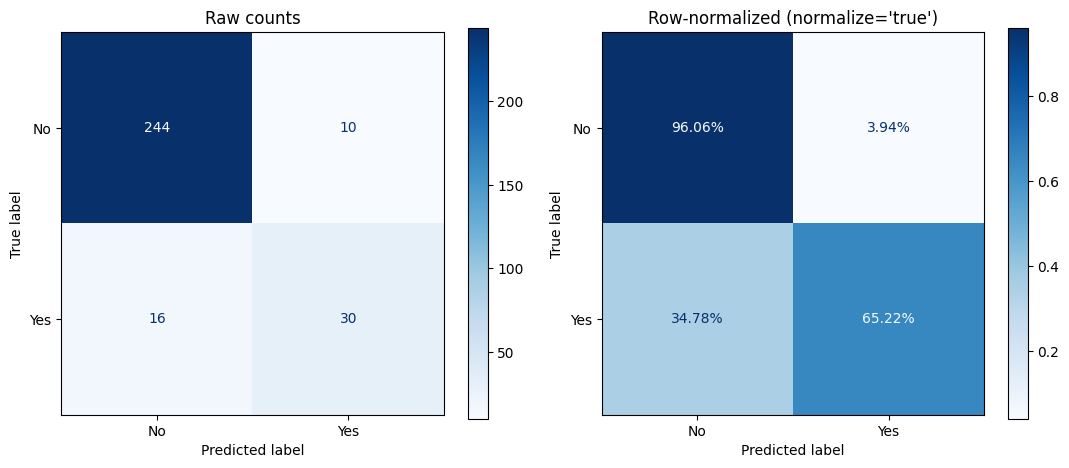

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_c, preds_c)
print("Raw confusion matrix:\n", cm)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No", "Yes"]).plot(ax=axes[0], cmap="Blues")
axes[0].set_title("Raw counts")

cm_normalized = confusion_matrix(y_test_c, preds_c, normalize="true")   # row-normalized -> per-class recall visible directly
ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=["No", "Yes"]).plot(ax=axes[1], cmap="Blues", values_format=".2%")
axes[1].set_title("Row-normalized (normalize='true')")

plt.tight_layout()
plt.show()


### Parameter Explanation
- `normalize=` — `'true'` normalizes by row (actual class) — the diagonal directly shows **per-class recall**; `'pred'` normalizes by column (predicted class) — the diagonal directly shows **per-class precision**; `'all'` normalizes by the grand total.
- `ConfusionMatrixDisplay` is a thin Matplotlib wrapper (part of Scikit-learn's `*Display` family, e.g., also `RocCurveDisplay`, `PrecisionRecallDisplay` — Chapter 29) — it's `.plot()`'d directly, no need to build the `imshow` heatmap manually as in the from-scratch version.

### Connecting Confusion Matrices to Business Decisions


In [6]:
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives:  {tn}  (correctly predicted 'No')")
print(f"False Positives: {fp}  (incorrectly flagged 'Yes' -- a false alarm)")
print(f"False Negatives: {fn}  (missed a genuine 'Yes' -- a miss)")
print(f"True Positives:  {tp}  (correctly caught 'Yes')")

# A concrete business-cost translation, exactly the Ch 94 (Matplotlib course-style) exercise
cost_per_fp = 50     # e.g., cost of an unnecessary manual review
cost_per_fn = 500     # e.g., cost of a missed fraud case
total_cost = fp * cost_per_fp + fn * cost_per_fn
print(f"\nEstimated business cost at this threshold: ${total_cost:,}")
print("(fp * cost_per_fp + fn * cost_per_fn -- this cost-translation exercise is exactly")
print(" what motivates Chapter 30's threshold optimization: the DEFAULT 0.5 threshold")
print(" is almost never the cost-minimizing one.)")


True Negatives:  244  (correctly predicted 'No')
False Positives: 10  (incorrectly flagged 'Yes' -- a false alarm)
False Negatives: 16  (missed a genuine 'Yes' -- a miss)
True Positives:  30  (correctly caught 'Yes')

Estimated business cost at this threshold: $8,500
(fp * cost_per_fp + fn * cost_per_fn -- this cost-translation exercise is exactly
 what motivates Chapter 30's threshold optimization: the DEFAULT 0.5 threshold
 is almost never the cost-minimizing one.)


### Common Mistakes
- Reading raw confusion matrix counts without normalizing when comparing across classes of very different sizes — `normalize='true'` (per-class recall) is usually the more directly comparable view for imbalanced problems.
- Never translating the confusion matrix into an actual estimated business cost — the raw TP/TN/FP/FN counts are inputs to a business decision, not the decision itself.

### Interview Insight
**Q: What does `normalize='true'` in `confusion_matrix()` show you directly on the diagonal, and why is that often more useful than raw counts for imbalanced data?**
A: `normalize='true'` divides each row by that row's total (the actual class count), so the diagonal directly shows each class's **recall** — the fraction of that class's true members correctly identified. For an imbalanced dataset, raw counts can make the majority class's large numbers dominate visually even if the minority class's recall is genuinely poor; the normalized view puts both classes on the same 0–1 scale, making a weak minority-class recall immediately visible rather than hidden by scale.

### Quiz (Chapter 28)
1. What does `normalize='pred'` show on the diagonal, versus `normalize='true'`?
2. How would you translate a confusion matrix into an estimated business cost, given per-error-type costs?
3. Why might raw confusion matrix counts be misleading for a severely imbalanced classification problem?


---
# CHAPTER 29 — ROC / PR ANALYSIS

## 1. Concept
Scikit-learn's `RocCurveDisplay`/`PrecisionRecallDisplay` are the official, maintained equivalents of the from-scratch ROC/PR curve code built in the Matplotlib course (Chapters 54–55) — same underlying concepts, now via the dedicated, one-line API.


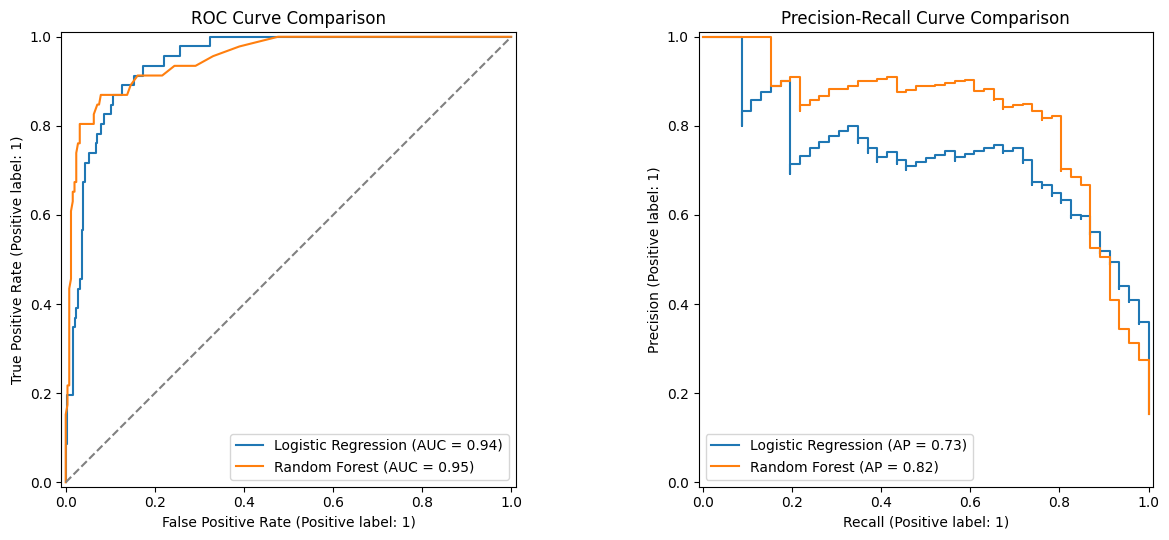

In [7]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
from sklearn.ensemble import RandomForestClassifier

rf_compare_metric = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train_c, y_train_c)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

RocCurveDisplay.from_estimator(model_c, X_test_c, y_test_c, ax=axes[0], name="Logistic Regression")
RocCurveDisplay.from_estimator(rf_compare_metric, X_test_c, y_test_c, ax=axes[0], name="Random Forest")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_title("ROC Curve Comparison")

PrecisionRecallDisplay.from_estimator(model_c, X_test_c, y_test_c, ax=axes[1], name="Logistic Regression")
PrecisionRecallDisplay.from_estimator(rf_compare_metric, X_test_c, y_test_c, ax=axes[1], name="Random Forest")
axes[1].set_title("Precision-Recall Curve Comparison")

plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- `RocCurveDisplay.from_estimator(model, X, y, ax=)` — a **single line** replaces the manual `roc_curve()` + `roc_auc_score()` + `ax.plot()` sequence from the Matplotlib course — it internally calls `predict_proba()` (or `decision_function()` if `predict_proba` isn't available), computes the curve, and plots it with the AUC already in the legend label.
- Passing `ax=axes[0]` twice, once per model, lets both curves render on the **same** Axes for direct comparison — exactly the Matplotlib-course pattern of building comparison charts, now driven by Scikit-learn's convenience wrapper instead of manual `roc_curve()` calls.

### Why ROC-AUC Can Be Misleading Under Imbalance — Reconfirmed With Real sklearn Output


In [8]:
from sklearn.metrics import roc_auc_score, average_precision_score

print(f"Positive class rate in test set: {y_test_c.mean():.3f}  (imbalanced, per this notebook's setup)")
print()
print(f"{'Model':<22}{'ROC-AUC':>10}{'Average Precision':>20}")
for name, m in [("Logistic Regression", model_c), ("Random Forest", rf_compare_metric)]:
    proba_m = m.predict_proba(X_test_c)[:, 1]
    print(f"{name:<22}{roc_auc_score(y_test_c, proba_m):>10.4f}{average_precision_score(y_test_c, proba_m):>20.4f}")

print("\nBoth curves LOOK strong on ROC-AUC; compare the RELATIVE gap on Average Precision")
print("specifically -- exactly the Matplotlib course's Chapter 55 lesson, now confirmed with")
print("Scikit-learn's own metric functions on genuinely imbalanced data.")


Positive class rate in test set: 0.153  (imbalanced, per this notebook's setup)

Model                    ROC-AUC   Average Precision
Logistic Regression       0.9449              0.7298
Random Forest             0.9516              0.8201

Both curves LOOK strong on ROC-AUC; compare the RELATIVE gap on Average Precision
specifically -- exactly the Matplotlib course's Chapter 55 lesson, now confirmed with
Scikit-learn's own metric functions on genuinely imbalanced data.


### Common Mistakes
- Manually recomputing `roc_curve()`/`precision_recall_curve()` and plotting them by hand when `RocCurveDisplay`/`PrecisionRecallDisplay` already do this correctly in one line — fine to know the manual mechanics (valuable for interviews and genuine understanding), but production/report code should generally prefer the maintained, tested convenience API.
- Reporting only ROC-AUC for an imbalanced problem, exactly the Matplotlib course's standing warning — now doubly easy to avoid, since `PrecisionRecallDisplay.from_estimator()` is equally one line.

### Interview Insight
**Q: What does `RocCurveDisplay.from_estimator(model, X, y)` do internally that you'd otherwise have to do manually?**
A: It calls the model's `predict_proba()` (falling back to `decision_function()` if unavailable) to get scores, computes `roc_curve()` and `roc_auc_score()` from those scores against the true labels, and renders the resulting curve with the AUC value automatically included in the legend — collapsing what would otherwise be several separate manual calls (`roc_curve`, `roc_auc_score`, `ax.plot`, legend construction) into one line, while remaining fully compatible with an externally-provided `ax=` for multi-model comparison charts.

### Quiz (Chapter 29)
1. What does `RocCurveDisplay.from_estimator()` call internally to get prediction scores?
2. Why is it still valuable to understand the manual `roc_curve()`/`precision_recall_curve()` mechanics even when using the `Display` convenience classes in practice?


---
# CHAPTER 30 — THRESHOLD OPTIMIZATION

## 1. Concept
`predict()`'s implicit 0.5 threshold is a default, not a business decision — this chapter builds the Scikit-learn-native version of the Matplotlib course's Chapter 56 threshold-sweep, now grounded in `sklearn.metrics` functions and connected directly to a cost-based business objective.


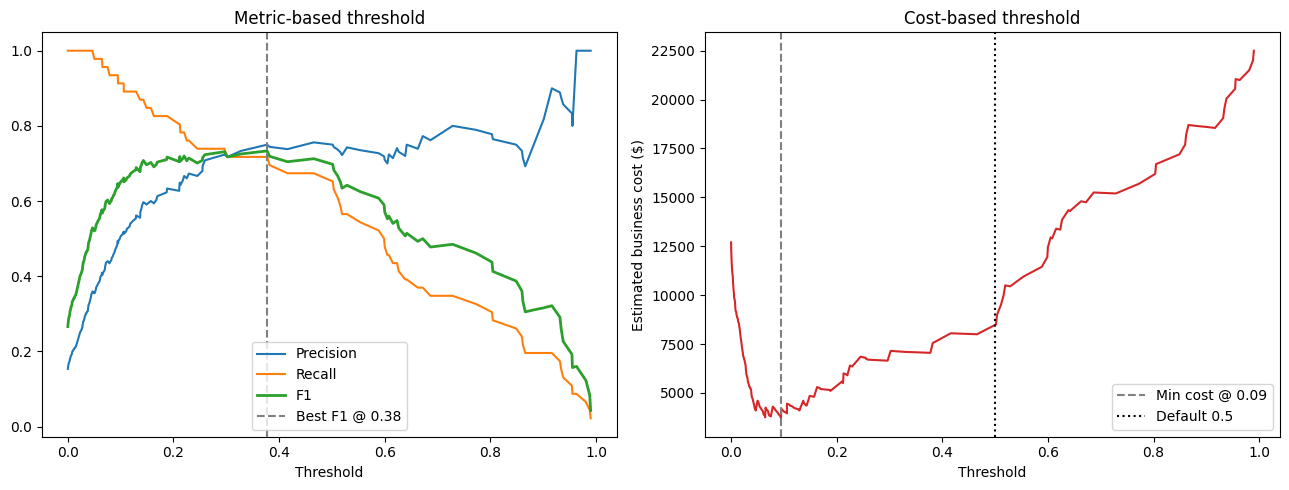

Default (0.5) threshold cost:     $8,500
Cost-minimizing threshold (0.095) cost: $3,700


In [9]:
from sklearn.metrics import precision_recall_curve, f1_score

precisions, recalls, thresholds = precision_recall_curve(y_test_c, proba_c)
precisions, recalls = precisions[:-1], recalls[:-1]   # trim, per the Matplotlib course's Ch 56 alignment note

f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

# Cost-based threshold selection: minimize FP*cost_fp + FN*cost_fn across ALL candidate thresholds
cost_fp, cost_fn = 50, 500
costs = []
for t in thresholds:
    preds_at_t = (proba_c >= t).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test_c, preds_at_t).ravel()
    costs.append(fp_t * cost_fp + fn_t * cost_fn)
costs = np.array(costs)

best_f1_idx = np.argmax(f1_scores)
best_cost_idx = np.argmin(costs)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(thresholds, precisions, label="Precision")
axes[0].plot(thresholds, recalls, label="Recall")
axes[0].plot(thresholds, f1_scores, label="F1", linewidth=2)
axes[0].axvline(thresholds[best_f1_idx], color="gray", linestyle="--", label=f"Best F1 @ {thresholds[best_f1_idx]:.2f}")
axes[0].set_xlabel("Threshold"); axes[0].legend(); axes[0].set_title("Metric-based threshold")

axes[1].plot(thresholds, costs, color="tab:red")
axes[1].axvline(thresholds[best_cost_idx], color="gray", linestyle="--", label=f"Min cost @ {thresholds[best_cost_idx]:.2f}")
axes[1].axvline(0.5, color="black", linestyle=":", label="Default 0.5")
axes[1].set_xlabel("Threshold"); axes[1].set_ylabel("Estimated business cost ($)")
axes[1].legend(); axes[1].set_title("Cost-based threshold")

plt.tight_layout()
plt.show()

print(f"Default (0.5) threshold cost:     ${costs[np.argmin(np.abs(thresholds - 0.5))]:,}")
print(f"Cost-minimizing threshold ({thresholds[best_cost_idx]:.3f}) cost: ${costs[best_cost_idx]:,}")


### Line-by-Line Explanation
- The cost-based sweep computes a full confusion matrix **at every candidate threshold**, translating it into a dollar cost via the same `cost_fp`/`cost_fn` weights introduced in Chapter 28 — this is the direct generalization of "best F1" into "actually cost-optimal," and typically produces a **different** recommended threshold than F1-optimization does, since F1 implicitly assumes precision and recall matter equally (a 1:1 cost ratio), while our business scenario here is a 1:10 ratio (`cost_fn` = 10× `cost_fp`).
- Comparing the default 0.5 threshold's cost against the cost-minimizing threshold's cost gives a concrete, dollar-denominated case for *why* threshold tuning matters — not an abstract metric improvement, but a directly quantified savings.

### Best Practices
- Whenever a rough cost ratio between false positives and false negatives is knowable (even approximately), optimize the threshold against that cost directly, rather than against a generic metric like F1 that assumes equal costs.
- Always compare the chosen threshold's outcome against the naive 0.5 default, quantified in the same units (dollars, or whatever the real cost is) — this is the concrete number that justifies the tuning effort to a business stakeholder.

### Interview Insight
**Q: You optimize a classifier's threshold for F1 score, but your manager says the model is still making too many costly errors. What's likely wrong?**
A: F1 assumes false positives and false negatives are equally costly (it's the harmonic mean, weighting precision and recall equally) — if the actual business cost ratio between a false positive and a false negative is meaningfully different from 1:1 (e.g., missing a fraud case costs 10x a false alarm), F1-optimization will land on a threshold that's mathematically balanced but not economically optimal. The fix is to directly compute the total estimated cost (`FP × cost_fp + FN × cost_fn`) across candidate thresholds and choose the one that minimizes *that*, rather than optimizing a proxy metric that doesn't reflect the true cost asymmetry.

### Quiz (Chapter 30)
1. Why can the F1-optimal threshold differ from the cost-optimal threshold?
2. How do you compute the estimated business cost at a specific threshold, given per-error-type costs?
3. What's the concrete, quantified argument for threshold tuning that a business stakeholder would find most persuasive?


---
# CHAPTER 31 — CALIBRATION

## 1. Concept
A model's `predict_proba()` output is not automatically a genuine, trustworthy probability — "**calibration**" specifically means: among all samples where the model predicts `P(positive) ≈ 0.7`, roughly 70% should actually turn out positive. A model can have excellent *ranking* ability (high ROC-AUC/AP) while being poorly *calibrated* — these are genuinely different properties.

## 2. Checking Calibration — `calibration_curve`


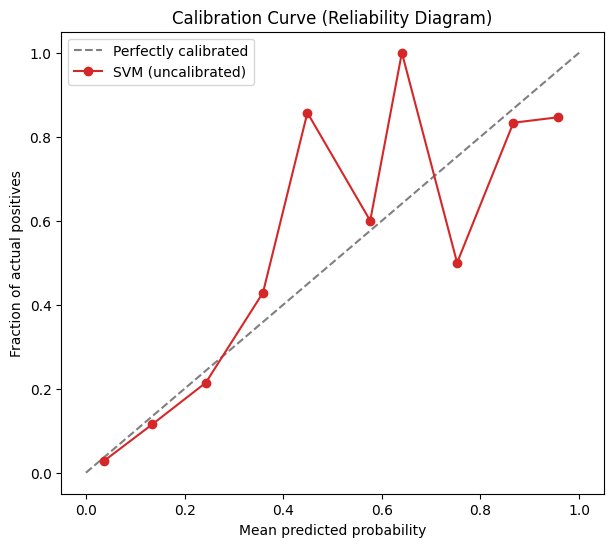

In [10]:
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.svm import SVC

# SVM decision_function-derived probabilities are a classic example of POORLY calibrated confidence scores
svm_uncalibrated = SVC(probability=True, random_state=42).fit(X_train_c, y_train_c)
proba_svm = svm_uncalibrated.predict_proba(X_test_c)[:, 1]

fraction_of_positives, mean_predicted_value = calibration_curve(y_test_c, proba_svm, n_bins=10)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfectly calibrated")
ax.plot(mean_predicted_value, fraction_of_positives, marker="o", color="tab:red", label="SVM (uncalibrated)")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Fraction of actual positives")
ax.set_title("Calibration Curve (Reliability Diagram)")
ax.legend()
plt.show()


### Interpretation
The diagonal dashed line represents perfect calibration — if the SVM's curve sits notably **below** the diagonal at a given predicted-probability bin, the model is **overconfident** in that region (e.g., it predicts 0.8 but only ~60% of those samples are actually positive); if **above**, it's underconfident. Deviations from the diagonal are exactly what `CalibratedClassifierCV` (next) corrects.

## 3. Fixing It — `CalibratedClassifierCV`


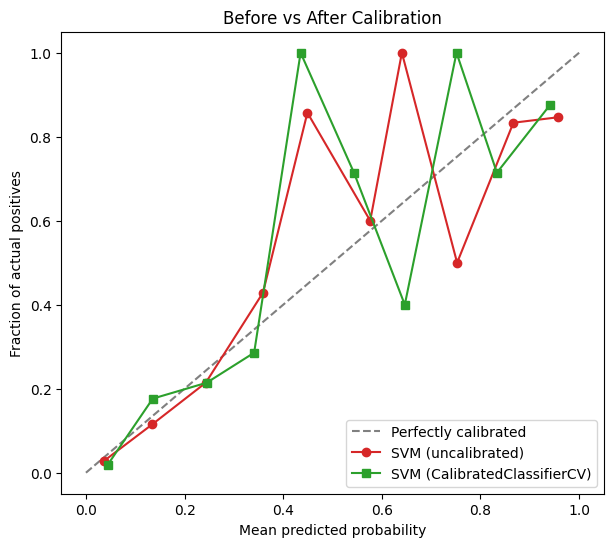

Brier score (uncalibrated): 0.0686  (lower is better)
Brier score (calibrated):   0.0684


In [11]:
from sklearn.metrics import brier_score_loss

calibrated_svm = CalibratedClassifierCV(SVC(random_state=42), method="sigmoid", cv=5)
calibrated_svm.fit(X_train_c, y_train_c)
proba_svm_calibrated = calibrated_svm.predict_proba(X_test_c)[:, 1]

frac_pos_cal, mean_pred_cal = calibration_curve(y_test_c, proba_svm_calibrated, n_bins=10)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfectly calibrated")
ax.plot(mean_predicted_value, fraction_of_positives, marker="o", color="tab:red", label="SVM (uncalibrated)")
ax.plot(mean_pred_cal, frac_pos_cal, marker="s", color="tab:green", label="SVM (CalibratedClassifierCV)")
ax.legend()
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Fraction of actual positives")
ax.set_title("Before vs After Calibration")
plt.show()

print(f"Brier score (uncalibrated): {brier_score_loss(y_test_c, proba_svm):.4f}  (lower is better)")
print(f"Brier score (calibrated):   {brier_score_loss(y_test_c, proba_svm_calibrated):.4f}")


### Parameter Explanation
- `method="sigmoid"` — fits a simple logistic (Platt scaling) curve mapping the model's raw scores to calibrated probabilities; `method="isotonic"` fits a more flexible, non-parametric monotonic mapping — generally more accurate with enough data, but can overfit on small datasets.
- `cv=5` — critically, `CalibratedClassifierCV` uses cross-validation internally to fit the calibration mapping on **held-out** predictions from the base model, not on the same data the base model was trained on — avoiding the same "fitting the correction to already-seen predictions" leakage risk that motivated `StackingClassifier`'s internal `cv=` (Chapter 20).
- **Brier score** — mean squared error between predicted probabilities and actual outcomes (0/1) — a standard single-number summary of overall probability quality, capturing both ranking *and* calibration in one metric, unlike ROC-AUC (ranking only).

### Common Mistakes
- Assuming `predict_proba()` is automatically well-calibrated for every model — it's a reasonable assumption for Logistic Regression and Naive Bayes (whose outputs are direct probabilistic model outputs by construction) but a poor assumption for SVM, and often somewhat poor for tree ensembles too (Chapter 19's leaf-probability discussion).
- Confusing calibration with ranking ability — a model can have excellent ROC-AUC (correctly ranks positives above negatives almost every time) while being badly calibrated (its absolute probability numbers are systematically too extreme or too conservative); they're independent properties, and improving one doesn't automatically improve the other.
- Calibrating on the same data the base model was trained on — reintroduces leakage; `CalibratedClassifierCV`'s internal `cv=` exists specifically to prevent this.

### Best Practices
- Check calibration explicitly (via `calibration_curve`/a reliability diagram) whenever the *actual probability values* matter to the application (e.g., risk scoring, expected-value calculations) — not just the ranking/classification decision.
- Use `CalibratedClassifierCV` to correct known poorly-calibrated model types (SVM being the classic case) before trusting their probability outputs for anything beyond simple thresholding.

### Interview Insight
**Q: A model has a ROC-AUC of 0.95 — excellent ranking ability. Does that mean its predicted probabilities are trustworthy for a risk-scoring application that needs actual probability values, not just rankings?**
A: Not necessarily. ROC-AUC only measures whether the model correctly *ranks* positive examples above negative examples across all thresholds — it says nothing about whether a predicted probability of, say, 0.8 genuinely corresponds to an 80% real-world likelihood. A model can have excellent ranking ability while being systematically over- or under-confident in its absolute probability values (calibration is an independent property from ranking). For a risk-scoring application where the actual probability number is used downstream (e.g., in an expected-value or premium calculation), calibration should be checked explicitly via a reliability diagram, and corrected with `CalibratedClassifierCV` if needed — a high ROC-AUC alone doesn't guarantee this.

### Quiz (Chapter 31)
1. What does it mean for a classifier to be "well-calibrated," precisely?
2. Why is SVM's `predict_proba()` a classic example of poor calibration, and what does `probability=True` actually do internally to produce it?
3. Why does `CalibratedClassifierCV` need its own internal `cv=`, rather than calibrating on the training set directly?
4. What does the Brier score measure that ROC-AUC does not?

### Chapter 31 Summary
- Calibration (do predicted probabilities match real-world frequencies) is a genuinely different property from ranking ability (ROC-AUC/AP) — a model can be strong on one and weak on the other.
- `calibration_curve` (reliability diagram) diagnoses miscalibration visually; `CalibratedClassifierCV` corrects it, using internal cross-validation to avoid leakage.
- Brier score is the standard single-number summary capturing both ranking and calibration quality together.

---

## END OF NOTEBOOK 6 — What You Should Now Be Able To Do
- Explain how Bayesian optimization (Optuna) differs from grid/random search, and know when the extra sophistication is worth it.
- Choose the correct evaluation metric — classification or regression — based on the actual business question, not habit or defaults.
- Build and interpret confusion matrices using Scikit-learn's native tools, including row/column normalization, and translate them into estimated business costs.
- Use `RocCurveDisplay`/`PrecisionRecallDisplay` for fast, correct multi-model comparison charts.
- Optimize a classification threshold against a real cost function, not just a proxy metric like F1.
- Diagnose and fix probability miscalibration with `calibration_curve` and `CalibratedClassifierCV`, and explain why ranking ability and calibration are independent properties.

## Before Moving to Notebook 7 (Chapters 32–38: Feature Selection, Mutual Information, Dimensionality Reduction, PCA Deeply, Unsupervised Learning/Clustering, Cluster Evaluation, Anomaly Detection)
